In [27]:
import pandas as pd
import numpy as np
dataset = pd.read_csv("/Users/nicoletimko/Desktop/cmu_year3/capstone_victimization/full_dataset/full_data.csv")

In [28]:
college_cols = [col for col in dataset.columns if col.startswith("college_status_")]

college_data = dataset[college_cols].replace([-1, -2, -3, -4, -5], np.nan)

missing_college = dataset[college_data.isna().all(axis=1)]

# Rows where every college_status column is missing
missing_college = dataset[dataset[college_cols].isna().all(axis=1)]

display(missing_college)

print("Number of rows:", len(missing_college))

,college_status_1997_01,college_status_1997_02,college_status_1997_03,college_status_1997_04,college_status_1997_05,college_status_1997_06,college_status_1997_07,college_status_1997_08,college_status_1997_09,college_status_1997_10,...,lived_with_both_bio_parents_at_birth,first_college_year,first_college_month,age_at_first_college,first_college_time,first_enroll_source,college_history,n_obs_17_20,timely_college,timely_category


Number of rows: 0


In [29]:
display(dataset[dataset["timely_college"].isna()])

,college_status_1997_01,college_status_1997_02,college_status_1997_03,college_status_1997_04,college_status_1997_05,college_status_1997_06,college_status_1997_07,college_status_1997_08,college_status_1997_09,college_status_1997_10,...,lived_with_both_bio_parents_at_birth,first_college_year,first_college_month,age_at_first_college,first_college_time,first_enroll_source,college_history,n_obs_17_20,timely_college,timely_category
123,-4,1,-4,-4,-4,-4,-4,-4,-4,-4,...,-4,NaN,NaN,NaN,NaN,NaN,Never observed enrolled,0,NaN,Never observed enrolled
301,-4,1,1,1,1,1,1,1,1,1,...,-4,NaN,NaN,NaN,NaN,NaN,Never observed enrolled,0,NaN,Never observed enrolled
318,-4,-4,-4,-4,-4,-4,1,-4,-4,-4,...,-4,NaN,NaN,NaN,NaN,NaN,Never observed enrolled,0,NaN,Never observed enrolled
329,-4,-4,1,-4,-4,-4,-4,-4,-4,-4,...,-4,NaN,NaN,NaN,NaN,NaN,Never observed enrolled,0,NaN,Never observed enrolled
360,-4,-4,-4,-4,-4,1,-4,-4,-4,-4,...,-4,NaN,NaN,NaN,NaN,NaN,Never observed enrolled,0,NaN,Never observed enrolled
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7912,-4,-4,-4,-4,-4,-4,-4,1,1,1,...,-4,NaN,NaN,NaN,NaN,NaN,Never observed enrolled,0,NaN,Never observed enrolled
8335,-4,-4,-4,-4,1,-4,-4,-4,-4,-4,...,-4,NaN,NaN,NaN,NaN,NaN,Never observed enrolled,0,NaN,Never observed enrolled
8448,-4,-4,-4,-4,-4,-4,-4,-4,-4,-4,...,-4,NaN,NaN,NaN,NaN,NaN,Never observed enrolled,0,NaN,Never observed enrolled
8486,-4,-4,-4,-4,1,-4,-4,-4,-4,-4,...,-4,NaN,NaN,NaN,NaN,NaN,Never observed enrolled,0,NaN,Never observed enrolled


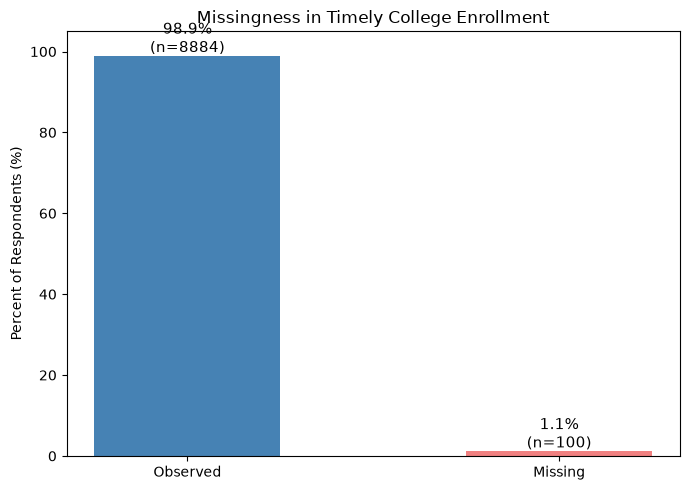

In [30]:
import matplotlib.pyplot as plt
import numpy as np

# Count missing and observed values
missing = dataset["timely_college"].isna().sum()
observed = dataset["timely_college"].notna().sum()

counts = [observed, missing]
percentages = np.array(counts) / len(dataset) * 100

fig, ax = plt.subplots(figsize=(7, 5))

bars = ax.bar(
    ["Observed", "Missing"],
    percentages,
    color=["steelblue", "lightcoral"],
    width=0.5
)

for bar, count, pct in zip(bars, counts, percentages):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 1,
        f"{pct:.1f}%\n(n={count})",
        ha="center",
        fontsize=11
    )

ax.set_ylabel("Percent of Respondents (%)")
ax.set_title("Missingness in Timely College Enrollment")
ax.set_ylim(0, 105)

plt.tight_layout()
plt.show()

In [31]:
victim_cols = ["violent_victim_2002", "violent_victim_2007", "violent_victim_2008", "violent_victim_2009", "violent_victim_2013"]

victim_data = dataset[victim_cols].apply(pd.to_numeric, errors="coerce")
reported_yes = (victim_data == 1).any(axis=1)
has_response = ((victim_data == 0) | (victim_data == 1)).any(axis=1)

dataset["victim_ever"] = pd.Series(pd.NA, index=dataset.index, dtype="Int64") # fills everything NA first
# so if not a valid response or 1 then will stay NA
dataset.loc[has_response, "victim_ever"] = 0
dataset.loc[reported_yes, "victim_ever"] = 1

/var/folders/kd/cctkl_m95r35__q677fkxkyh0000gn/T/ipykernel_84080/4016411155.py:7: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  dataset["victim_ever"] = pd.Series(pd.NA, index=dataset.index, dtype="Int64") # fills everything NA first


In [32]:
victim_age_cols = [
    "age_at_violent_victimization_2002",
    "age_at_violent_victimization_2007",
    "age_at_violent_victimization_2008",
    "age_at_violent_victimization_2009",
    "age_at_violent_victimization_2013"
]

def collect_victimization_ages(row):
    ages = []

    for col in victim_age_cols:
        age = row[col]

        # Keep valid reported ages only
        if pd.notna(age) and age > 0:
            ages.append(int(age))

    return ages


dataset["victimization_ages"] = dataset.apply(
    collect_victimization_ages,
    axis=1
)

/var/folders/kd/cctkl_m95r35__q677fkxkyh0000gn/T/ipykernel_84080/1667145520.py:22: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  dataset["victimization_ages"] = dataset.apply(


In [33]:
dataset["ever_enrolled"] = ((dataset["college_history"] == "Enrolled") | (dataset["college_history"] == "Grad program only")).astype(int)

/var/folders/kd/cctkl_m95r35__q677fkxkyh0000gn/T/ipykernel_84080/4157731737.py:1: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  dataset["ever_enrolled"] = ((dataset["college_history"] == "Enrolled") | (dataset["college_history"] == "Grad program only")).astype(int)


Did we want grad program?

In [34]:
dataset["college_history"].value_counts()

college_history
Enrolled                   5918
Never observed enrolled    3059
Grad program only             7
Name: count, dtype: int64

In [35]:
dataset

,college_status_1997_01,college_status_1997_02,college_status_1997_03,college_status_1997_04,college_status_1997_05,college_status_1997_06,college_status_1997_07,college_status_1997_08,college_status_1997_09,college_status_1997_10,...,age_at_first_college,first_college_time,first_enroll_source,college_history,n_obs_17_20,timely_college,timely_category,victim_ever,victimization_ages,ever_enrolled
0,-4,-4,-4,-4,-4,-4,1,1,1,1,...,17.0,23996.0,other month,Enrolled,48,1.0,Timely enrollment,0,[],1
1,-4,-4,-4,-4,1,1,1,1,1,1,...,18.0,24008.0,other month,Enrolled,48,1.0,Timely enrollment,0,[],1
2,-4,-4,-4,1,1,1,1,1,1,1,...,17.0,24018.0,other month,Enrolled,48,1.0,Timely enrollment,0,[],1
3,-4,1,1,1,1,1,1,1,1,1,...,20.0,24025.0,Jan/Feb/Sep,Enrolled,48,1.0,Timely enrollment,0,[],1
4,-4,-4,-4,-4,-4,-4,-4,-4,-4,-4,...,NaN,NaN,NaN,Never observed enrolled,48,0.0,Never observed enrolled,1,[20],0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
8979,-4,-4,-4,-4,-4,-4,-4,1,1,1,...,NaN,NaN,NaN,Never observed enrolled,43,0.0,Never observed enrolled,0,[],0
8980,-4,-4,-4,-4,-4,1,1,1,1,1,...,21.0,24070.0,other month,Enrolled,48,0.0,"Enrolled, but not timely",0,[],1
8981,-4,-4,-4,-4,-4,1,1,1,1,1,...,18.0,23984.0,other month,Enrolled,48,1.0,Timely enrollment,0,[],1
8982,-4,-4,-4,-4,-4,1,1,1,1,1,...,18.0,23991.0,other month,Enrolled,48,1.0,Timely enrollment,0,[],1


In [36]:
def create_outcome(row):
    ages = row["victimization_ages"]
    enrolled = row["ever_enrolled"]
    enrollment_age = row["age_at_first_college"]
    victim_ever = row["victim_ever"]

    # Missing victimization information
    if pd.isna(victim_ever):
        return pd.Series({
            "Y": pd.NA,
            "prior_victimization": pd.NA,
            "same_age_as_enrollment": pd.NA,

        })

    # Never reported victimization
    if victim_ever == 0:
        return pd.Series({
            "Y": 0,
            "prior_victimization": 0,
            "same_age_as_enrollment": 0,

        })

    # Make sure victimization ages are stored as a list
    if not isinstance(ages, list):
        valid_ages = []

    else:
        valid_ages = [
            age for age in ages
            if pd.notna(age) and age > 0
        ]

    # Reported victimization, but no valid age is available
    if len(valid_ages) == 0:
        return pd.Series({
            "Y": pd.NA,
            "prior_victimization": pd.NA,
            "same_age_as_enrollment": pd.NA,
        })

    # Missing college-enrollment status
    if pd.isna(enrolled):
        return pd.Series({
            "Y": pd.NA,
            "prior_victimization": pd.NA,
            "same_age_as_enrollment": pd.NA,
        })

    # --------------------------------------------------
    # Never enrolled
    # --------------------------------------------------

    if enrolled == 0:

        # Victimized during the outcome period
        during_18_24 = any(
            18 <= age <= 24
            for age in valid_ages
        )

        # For never-enrolled people, prior means before age 17
        before_18 = any(
            age < 18
            for age in valid_ages
        )

        return pd.Series({
            "Y": int(during_18_24),
            "prior_victimization": int(before_18),
            "same_age_as_enrollment": 0,
        })

    # --------------------------------------------------
    # Enrolled
    # --------------------------------------------------

    # Enrolled, but first enrollment age is unavailable
    if pd.isna(enrollment_age):
        return pd.Series({
            "Y": pd.NA,
            "prior_victimization": pd.NA,
            "same_age_as_enrollment": pd.NA,
        })

    # Victimization before first enrollment
    prior = any(
        age < enrollment_age
        for age in valid_ages
    )

    # Victimization at the same age as first enrollment
    same_age = any(
        age == enrollment_age
        for age in valid_ages
    )

    # Victimization after enrollment during ages 18–24
    after_enrollment_18_24 = any(
        age > enrollment_age
        and 18 <= age <= 24
        for age in valid_ages
    )

    # Victimization after both enrollment and age 24
    after_enrollment_and_24 = any(
        age > enrollment_age
        and age > 24
        for age in valid_ages
    )

    # Definite qualifying outcome
    if after_enrollment_18_24:
        outcome = 1

    # Victimization only known to be at the same age
    elif same_age:
        outcome = pd.NA

    else:
        outcome = 0

    return pd.Series({
        "Y": outcome,
        "prior_victimization": int(prior),
        "same_age_as_enrollment": int(same_age),
    })

In [37]:
outcome_columns = [
    "Y",
    "prior_victimization",
    "same_age_as_enrollment",
]

dataset[outcome_columns] = dataset.apply(
    create_outcome,
    axis=1
)

for col in outcome_columns:
    dataset[col] = dataset[col].astype("Int64")

/var/folders/kd/cctkl_m95r35__q677fkxkyh0000gn/T/ipykernel_84080/2438251932.py:7: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  dataset[outcome_columns] = dataset.apply(
/var/folders/kd/cctkl_m95r35__q677fkxkyh0000gn/T/ipykernel_84080/2438251932.py:7: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  dataset[outcome_columns] = dataset.apply(
/var/folders/kd/cctkl_m95r35__q677fkxkyh0000gn/T/ipykernel_84080/2438251932.py:7: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many t

In [38]:
display(dataset)

,college_status_1997_01,college_status_1997_02,college_status_1997_03,college_status_1997_04,college_status_1997_05,college_status_1997_06,college_status_1997_07,college_status_1997_08,college_status_1997_09,college_status_1997_10,...,college_history,n_obs_17_20,timely_college,timely_category,victim_ever,victimization_ages,ever_enrolled,Y,prior_victimization,same_age_as_enrollment
0,-4,-4,-4,-4,-4,-4,1,1,1,1,...,Enrolled,48,1.0,Timely enrollment,0,[],1,0,0,0
1,-4,-4,-4,-4,1,1,1,1,1,1,...,Enrolled,48,1.0,Timely enrollment,0,[],1,0,0,0
2,-4,-4,-4,1,1,1,1,1,1,1,...,Enrolled,48,1.0,Timely enrollment,0,[],1,0,0,0
3,-4,1,1,1,1,1,1,1,1,1,...,Enrolled,48,1.0,Timely enrollment,0,[],1,0,0,0
4,-4,-4,-4,-4,-4,-4,-4,-4,-4,-4,...,Never observed enrolled,48,0.0,Never observed enrolled,1,[20],0,1,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
8979,-4,-4,-4,-4,-4,-4,-4,1,1,1,...,Never observed enrolled,43,0.0,Never observed enrolled,0,[],0,0,0,0
8980,-4,-4,-4,-4,-4,1,1,1,1,1,...,Enrolled,48,0.0,"Enrolled, but not timely",0,[],1,0,0,0
8981,-4,-4,-4,-4,-4,1,1,1,1,1,...,Enrolled,48,1.0,Timely enrollment,0,[],1,0,0,0
8982,-4,-4,-4,-4,-4,1,1,1,1,1,...,Enrolled,48,1.0,Timely enrollment,0,[],1,0,0,0


In [39]:
dataset.to_csv("/Users/nicoletimko/Desktop/capstone_victimization/full_dataset/data_with_Y.csv")

OSError: Cannot save file into a non-existent directory: '/Users/nicoletimko/Desktop/capstone_victimization/full_dataset'